# Speaker–topic ownership, participation equality, and turn-taking

This notebook connects semantic topic chunks to anonymous diarization speakers through exact timestamp overlap. It answers three related questions:

1. **Participation equality:** how evenly is speaking time distributed within each conversation?
2. **Topic ownership:** does a topic involve many speakers, or is it largely owned by one voice?
3. **Turn-taking dynamics:** how quickly does the floor move, and how does participation change from opening to closing?

The analysis resolves 264 diarization files to 219 canonical conversations so duplicate uploads do not receive extra weight. Speaker labels remain local to each recording and must not be interpreted as identities.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from arvamusfestivali_transcripts.diarization_analysis import (
    align_topic_chunks_to_speakers,
    participation_metrics,
    speaker_transition_rows,
    summarize_conversation,
)
from arvamusfestivali_transcripts.text_quality import has_meaningful_text

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# Set this to a canonical episode ID to inspect another conversation in detail.
SELECTED_EPISODE_ID = None
MIN_TOPIC_SPEECH_SECONDS = 30.0

## Load metadata, topic chunks, and canonical episode mappings

The combined Jev export is used because the year-specific exports cover only subsets of the SoundCloud upload year. Duplicate episode IDs are expanded from the canonical talk metadata.

In [2]:
project_root = Path.cwd().resolve()
if not (project_root / "data/diarization/2026").exists():
    project_root = project_root.parent

diarization_dir = project_root / "data/diarization/2026"
result_root = project_root / "data/topic-analysis/results"
for required in [
    diarization_dir,
    result_root / "jev-semantic-all/assignments.parquet",
    result_root / "segment-dataset/all-segments.parquet",
    result_root / "talk-metadata/talks.parquet",
]:
    if not required.exists():
        raise FileNotFoundError(required)

talks = pd.read_parquet(
    result_root / "talk-metadata/talks.parquet",
    columns=["episode_id", "duplicate_episode_ids", "title", "organizer", "programme_stage"],
)
talks["episode_id"] = talks.episode_id.astype(str)
alias_rows = [
    {
        "episode_id": str(alias),
        "canonical_episode_id": str(row.episode_id),
        "title": row.title,
        "organizer": row.organizer,
        "programme_stage": row.programme_stage,
    }
    for row in talks.itertuples()
    for alias in json.loads(row.duplicate_episode_ids)
]
episode_aliases = pd.DataFrame(alias_rows).drop_duplicates("episode_id")

available_episode_ids = {path.stem for path in diarization_dir.glob("*.json")}
available_aliases = episode_aliases[episode_aliases.episode_id.isin(available_episode_ids)].copy()
if set(available_episode_ids) != set(available_aliases.episode_id):
    raise ValueError("Some diarization files are absent from canonical talk metadata")

canonical_files = {}
for canonical_id, group in available_aliases.groupby("canonical_episode_id"):
    aliases = sorted(group.episode_id)
    selected = canonical_id if canonical_id in aliases else aliases[0]
    canonical_files[canonical_id] = diarization_dir / f"{selected}.json"

assignments = pd.read_parquet(
    result_root / "jev-semantic-all/assignments.parquet",
    columns=[
        "segment_key", "jev_topic_id", "jev_topic_name",
        "jev_high_level_id", "jev_high_level_name",
    ],
)
segment_timing = pd.read_parquet(
    result_root / "segment-dataset/all-segments.parquet",
    columns=["segment_key", "episode_id", "start_seconds", "end_seconds", "text"],
)
meaningful_segment_mask = segment_timing.text.map(has_meaningful_text)
discarded_topic_segment_count = int((~meaningful_segment_mask).sum())
discarded_segment_keys = set(segment_timing.loc[~meaningful_segment_mask, "segment_key"])
segment_timing = segment_timing.loc[meaningful_segment_mask].copy()
assignments = assignments.loc[~assignments.segment_key.isin(discarded_segment_keys)].copy()
print(f"Discarded {discarded_topic_segment_count:,} empty/punctuation-only topic segments.")
topic_chunks = assignments.merge(
    segment_timing, on="segment_key", how="left", validate="one_to_one"
)
if topic_chunks.episode_id.isna().any():
    raise ValueError("Some topic assignments do not match segment timing")
topic_chunks["episode_id"] = topic_chunks.episode_id.astype(str)
topic_chunks["chunk_duration_seconds"] = (
    topic_chunks.end_seconds - topic_chunks.start_seconds
).clip(lower=0)

assert len(available_episode_ids) == 264
assert len(canonical_files) == 219
assert set(canonical_files) == set(topic_chunks.episode_id)
print(f"Loaded {len(available_episode_ids)} files → {len(canonical_files)} canonical conversations.")
print(f"Loaded {len(topic_chunks):,} semantic topic chunks with complete canonical coverage.")

Discarded 0 empty/punctuation-only topic segments.
Loaded 264 files → 219 canonical conversations.
Loaded 4,126 semantic topic chunks with complete canonical coverage.


## Align topic chunks to speaker turns

Every positive interval intersection becomes one allocation row. A chunk may contribute time to several speakers; overlapping speech can therefore make summed speaker overlap exceed wall-clock chunk duration. This is intentional and is reported explicitly.

In [3]:
alignment_rows = []
conversation_rows = []
transition_rows = []
payloads = {}

metadata_by_canonical = (
    available_aliases.drop_duplicates("canonical_episode_id")
    .set_index("canonical_episode_id")
)

for canonical_id, path in sorted(canonical_files.items()):
    payload = json.loads(path.read_text(encoding="utf-8"))
    payloads[canonical_id] = payload
    turns = payload.get("turns", [])
    metadata = metadata_by_canonical.loc[canonical_id]

    chunks = (
        topic_chunks.loc[topic_chunks.episode_id.eq(canonical_id)]
        .rename(columns={
            "jev_topic_id": "detailed_topic_id",
            "jev_topic_name": "detailed_topic_name",
            "jev_high_level_id": "high_level_id",
            "jev_high_level_name": "high_level_name",
        })[
            [
                "start_seconds", "end_seconds", "segment_key",
                "detailed_topic_id", "detailed_topic_name",
                "high_level_id", "high_level_name",
            ]
        ]
        .to_dict("records")
    )
    aligned = align_topic_chunks_to_speakers(chunks, turns)
    for row in aligned:
        row.update({
            "canonical_episode_id": canonical_id,
            "title": metadata.title,
        })
    alignment_rows.extend(aligned)

    summary = summarize_conversation(payload)
    transitions = speaker_transition_rows(turns)
    for row in transitions:
        row["canonical_episode_id"] = canonical_id
        row["title"] = metadata.title
    transition_rows.extend(transitions)

    total_minutes = summary["total_speech_seconds"] / 60
    summary.update({
        "canonical_episode_id": canonical_id,
        "title": metadata.title,
        "organizer": metadata.organizer,
        "programme_stage": metadata.programme_stage,
        "speaker_switches": sum(row["transition_count"] for row in transitions),
        "switches_per_speech_minute": (
            sum(row["transition_count"] for row in transitions) / total_minutes
            if total_minutes else np.nan
        ),
    })
    conversation_rows.append(summary)

alignment = pd.DataFrame(alignment_rows)
conversations = pd.DataFrame(conversation_rows).sort_values("canonical_episode_id").reset_index(drop=True)
transitions = pd.DataFrame(transition_rows)

speaker_topic = (
    alignment.groupby([
        "canonical_episode_id", "title", "speaker",
        "high_level_id", "high_level_name",
        "detailed_topic_id", "detailed_topic_name",
    ], as_index=False)
    .overlap_seconds.sum()
)

matched_chunks = alignment[["canonical_episode_id", "segment_key"]].drop_duplicates()
chunk_coverage = len(matched_chunks) / len(topic_chunks)
aligned_speech = alignment.overlap_seconds.sum()
chunk_wall_time = topic_chunks.chunk_duration_seconds.sum()

print(f"Aligned rows: {len(alignment):,}")
print(f"Topic chunks with at least one speaker: {len(matched_chunks):,}/{len(topic_chunks):,} ({chunk_coverage:.1%})")
print(f"Speaker-overlap seconds / topic wall time: {aligned_speech / chunk_wall_time:.1%}")
display(conversations.head())

Aligned rows: 144,310
Topic chunks with at least one speaker: 4,126/4,126 (100.0%)
Speaker-overlap seconds / topic wall time: 92.7%


,episode_id,segment_count,valid_segment_count,invalid_segment_count,short_segment_count,text_cue_count,discarded_text_cue_count,unique_speakers,total_speech_seconds,median_segment_seconds,dominant_speaker_share,top_two_speaker_share,normalized_hhi,gini,effective_speaker_count,canonical_episode_id,title,organizer,programme_stage,speaker_switches,switches_per_speech_minute
0,2247188684,837,837,0,50,1187,6,8,"4,765.434",4.101,0.381,0.625,0.147,0.547,3.940,2247188684,Kas kiirustades elad kauem?,Eesti Personalijuhtimise Ühing PARE,17 Tööelu,206,2.594
1,2247188687,826,826,0,124,1234,9,11,"5,106.642",3.645,0.219,0.396,0.073,0.468,6.360,2247188687,Kes koristab?!,Eesti Personalijuhtimise Ühing PARE,17 Tööelu,415,4.876
2,2247188690,1127,1127,0,158,1139,12,8,"4,702.573",2.852,0.355,0.525,0.102,0.448,4.668,2247188690,Kas kõik on kiusamine?,Eesti Personalijuhtimise Ühing PARE,17 Tööelu,430,5.486
3,2247188693,770,770,0,88,1163,13,7,"4,999.245",3.830,0.264,0.499,0.077,0.377,4.785,2247188693,Töökius otse laval,Eesti Personalijuhtimise Ühing PARE,17 Tööelu,318,3.817
4,2247188696,935,935,0,118,1121,15,15,"4,758.010",2.565,0.404,0.564,0.169,0.660,4.450,2247188696,Juhi võim versus töötaja julgus,Eesti Personalijuhtimise Ühing PARE,17 Tööelu,359,4.527


## Participation equality across conversations

Low dominant-speaker share, Gini, and normalized HHI indicate more equal participation. Effective speaker count asks how many equally active speakers would produce the observed duration concentration.

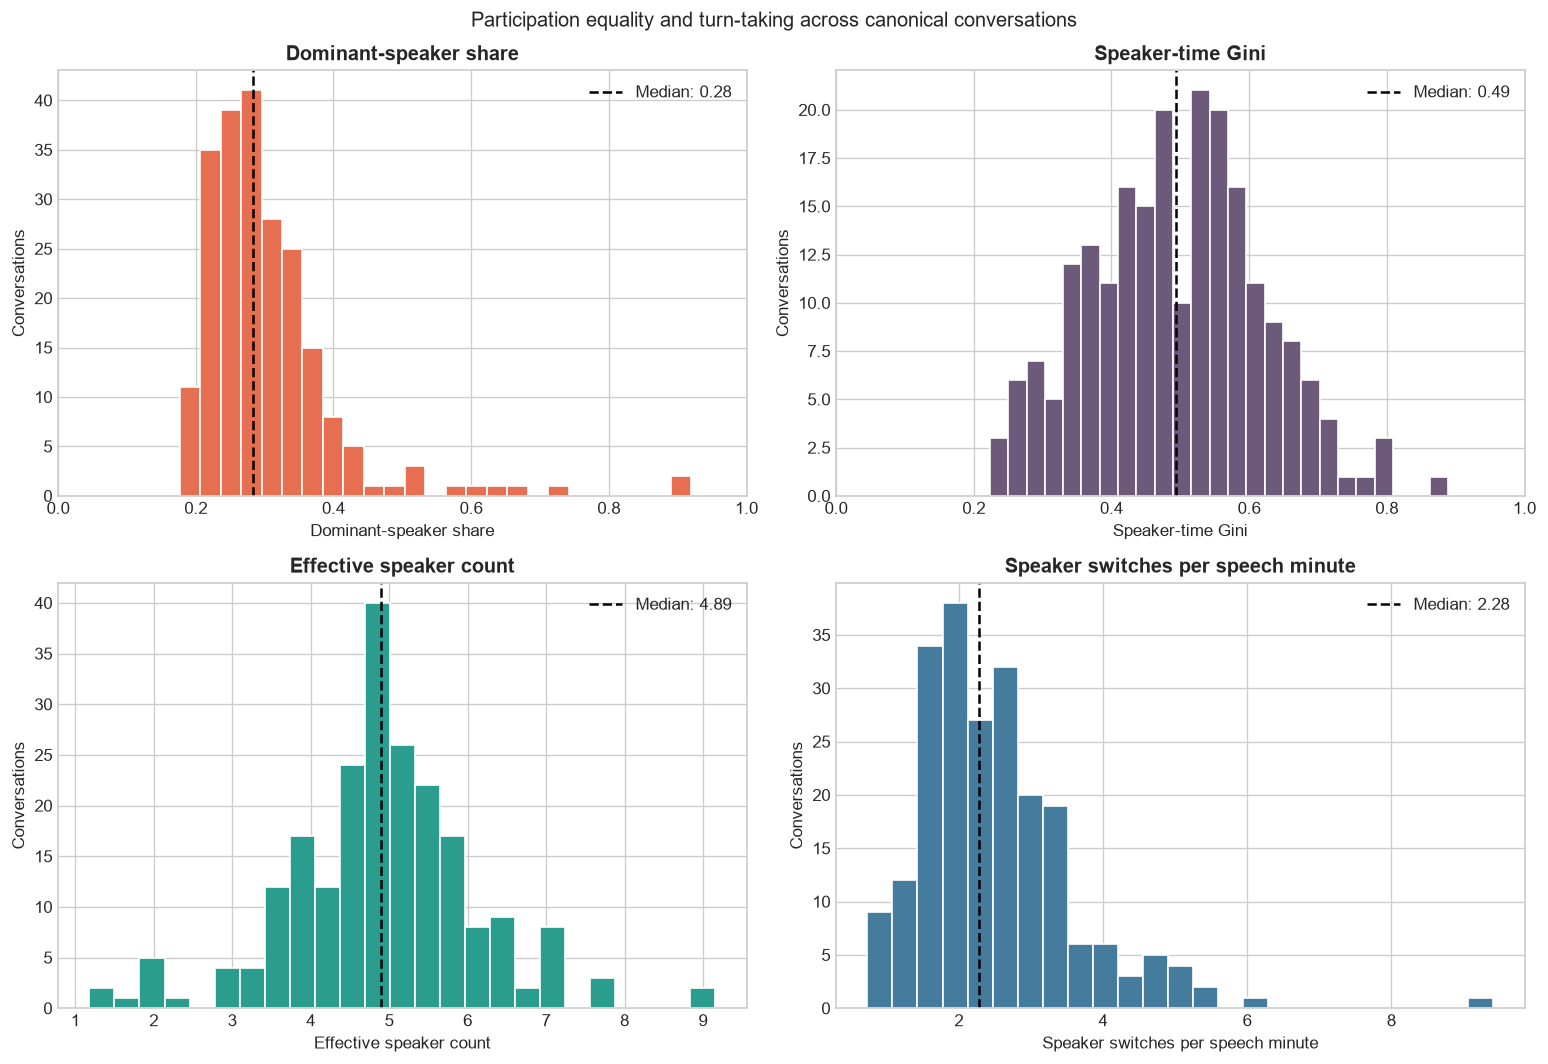

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
specs = [
    ("dominant_speaker_share", "Dominant-speaker share", (0, 1), "#e76f51"),
    ("gini", "Speaker-time Gini", (0, 1), "#6d597a"),
    ("effective_speaker_count", "Effective speaker count", None, "#2a9d8f"),
    ("switches_per_speech_minute", "Speaker switches per speech minute", None, "#457b9d"),
]
for ax, (column, title, limits, color) in zip(axes.flat, specs, strict=True):
    values = conversations[column].dropna()
    ax.hist(values, bins=25, color=color, edgecolor="white")
    ax.axvline(values.median(), color="black", linestyle="--", label=f"Median: {values.median():.2f}")
    ax.set(title=title, xlabel=title, ylabel="Conversations")
    if limits:
        ax.set_xlim(*limits)
    ax.legend()
fig.suptitle("Participation equality and turn-taking across canonical conversations")
fig.tight_layout()
plt.show()

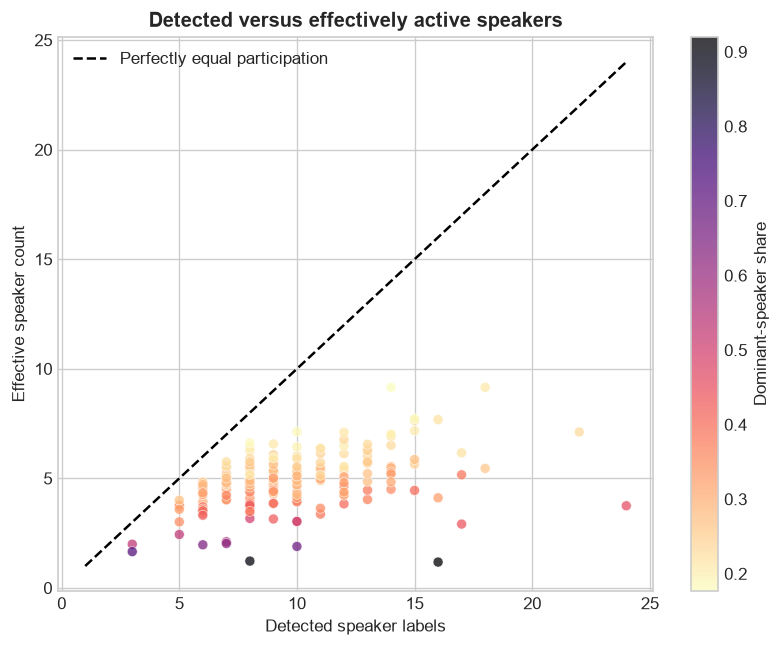

Most equal multi-speaker conversations


,canonical_episode_id,title,unique_speakers,effective_speaker_count,dominant_speaker_share,gini,switches_per_speech_minute
111,2323554809,Miks kaasamine pekki läheb_,5,4.005,0.267,0.223,2.651
105,2323554791,Parlamendierakondade esimeeste debatt,8,6.620,0.183,0.240,3.077
172,2397177240,Kultuur on majandusharu,7,5.755,0.227,0.241,1.749
50,2289585014,Küberkurjategija mõtteviis. Kuidas mõelda nagu...,6,4.826,0.261,0.257,1.835
26,2267420987,Kliimatark metsandus. Kuidas kohaneda ja tegut...,6,4.803,0.263,0.260,1.834
33,2271676352,Ajalugu oleviku teejuhina – kristallkuul või k...,6,4.788,0.264,0.263,2.063
29,2267420996,"Eesti inimesed soovivad, ökoloogid soovitavad ...",8,6.440,0.198,0.266,1.822
68,2300040491,Lastekaitsetöö nähtamatu vastutus ja avalik kr...,7,5.538,0.214,0.274,1.278
140,2395857129,Pagulus ja rahvus,7,5.569,0.227,0.275,1.777
150,2395991460,Kriis ei vabasta juhtimisest,6,4.721,0.282,0.278,2.775


Most concentrated multi-speaker conversations


,canonical_episode_id,title,unique_speakers,effective_speaker_count,dominant_speaker_share,gini,switches_per_speech_minute
203,2400184977,"Post-it, pastakas ja AI-agent - Eesti.ai prakt...",16,1.180,0.920,0.889,2.243
205,2400184983,"Post-it, pastakas ja AI-agent - Eesti.ai prakt...",8,1.225,0.902,0.801,2.692
197,2400164904,Kuidas toetada lapse keele ja kõne arengut lii...,10,1.894,0.679,0.796,2.540
52,2289585020,Zoomer vs Boomer. Arija ja Marii Laser Techist...,24,3.750,0.456,0.787,3.879
125,2393585466,Matemaatikatund ja -ring kui mõtlemise laborid,17,2.914,0.441,0.772,5.570
39,2277338243,Maailmahariduslik mälumäng ja mõtteharjutused ...,16,4.112,0.325,0.741,9.412
121,2387966373,Miks peab elektriga kauplema börsil_ (1),7,2.027,0.622,0.722,1.359
116,2383011948,Nõusolek – seksikuse summutaja või hoopis võim...,10,3.033,0.431,0.711,2.374
10,2250797867,"Loodus, majandus ja julgeolek. Kas valida tule...",13,4.038,0.369,0.706,2.013
54,2289585026,Kuidas kaitsta lapsi AI-ajastul internetis kur...,7,2.107,0.566,0.706,2.356


In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    conversations.unique_speakers,
    conversations.effective_speaker_count,
    c=conversations.dominant_speaker_share,
    cmap="magma_r",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.4,
)
limit = max(conversations.unique_speakers.max(), conversations.effective_speaker_count.max())
ax.plot([1, limit], [1, limit], color="black", linestyle="--", label="Perfectly equal participation")
ax.set(
    title="Detected versus effectively active speakers",
    xlabel="Detected speaker labels",
    ylabel="Effective speaker count",
)
fig.colorbar(scatter, ax=ax, label="Dominant-speaker share")
ax.legend()
plt.show()

equality_columns = [
    "canonical_episode_id", "title", "unique_speakers", "effective_speaker_count",
    "dominant_speaker_share", "gini", "switches_per_speech_minute",
]
print("Most equal multi-speaker conversations")
display(conversations.loc[conversations.unique_speakers.ge(2)].nsmallest(10, "gini")[equality_columns])
print("Most concentrated multi-speaker conversations")
display(conversations.loc[conversations.unique_speakers.ge(2)].nlargest(10, "gini")[equality_columns])

## Topic ownership

Metrics are calculated independently for every conversation–topic combination from overlapping speaker time. Combinations with under 30 seconds of aligned speech are retained in `topic_instances_all` but excluded from comparison plots by default.

In [6]:
topic_instance_rows = []
for (episode_id, high_level_id, high_level_name), group in speaker_topic.groupby([
    "canonical_episode_id", "high_level_id", "high_level_name"
]):
    durations = group.groupby("speaker").overlap_seconds.sum().to_dict()
    metrics = participation_metrics(durations)
    topic_instance_rows.append({
        "canonical_episode_id": episode_id,
        "title": group.title.iloc[0],
        "high_level_id": high_level_id,
        "high_level_name": high_level_name,
        **metrics,
    })

topic_instances_all = pd.DataFrame(topic_instance_rows)
topic_instances = topic_instances_all.loc[
    topic_instances_all.total_speech_seconds.ge(MIN_TOPIC_SPEECH_SECONDS)
].copy()

topic_summary = (
    topic_instances.groupby(["high_level_id", "high_level_name"])
    .agg(
        conversation_topics=("canonical_episode_id", "size"),
        aligned_speech_hours=("total_speech_seconds", lambda values: values.sum() / 3600),
        median_active_speakers=("unique_speakers", "median"),
        median_effective_speakers=("effective_speaker_count", "median"),
        median_dominant_share=("dominant_speaker_share", "median"),
        median_gini=("gini", "median"),
    )
    .sort_values("conversation_topics", ascending=False)
)
print(f"Topic instances: {len(topic_instances_all):,} total; {len(topic_instances):,} with at least {MIN_TOPIC_SPEECH_SECONDS:.0f} aligned seconds.")
display(topic_summary)

Topic instances: 662 total; 662 with at least 30 aligned seconds.


,,conversation_topics,aligned_speech_hours,median_active_speakers,median_effective_speakers,median_dominant_share,median_gini
high_level_id,high_level_name,,,,,,
unassigned,Määramata,155,17.984,5.000,2.436,0.536,0.489
education,"Haridus, õppimine ja oskused",72,38.726,7.000,4.028,0.366,0.457
governance,"Riigijuhtimine, kodanikuühiskond ja õigus",44,16.889,5.000,2.867,0.431,0.464
climate,"Kliima, rohepööre ja kestlik tarbimine",36,12.636,5.000,3.508,0.402,0.391
wellbeing,"Vaimne tervis, tervisekäitumine ja ennetus",34,15.364,6.000,3.740,0.362,0.452
work,"Tööelu, juhtimine ja töötajate õigused",34,21.344,6.000,4.009,0.361,0.462
healthcare,"Tervishoid, ravi ja terviseandmed",29,25.911,8.000,4.651,0.297,0.454
economy,"Majandus, ettevõtlus ja innovatsioon",29,8.633,5.000,3.014,0.487,0.470
ai,Tehisintellekt ja digitehnoloogia,29,12.481,6.000,3.306,0.423,0.460


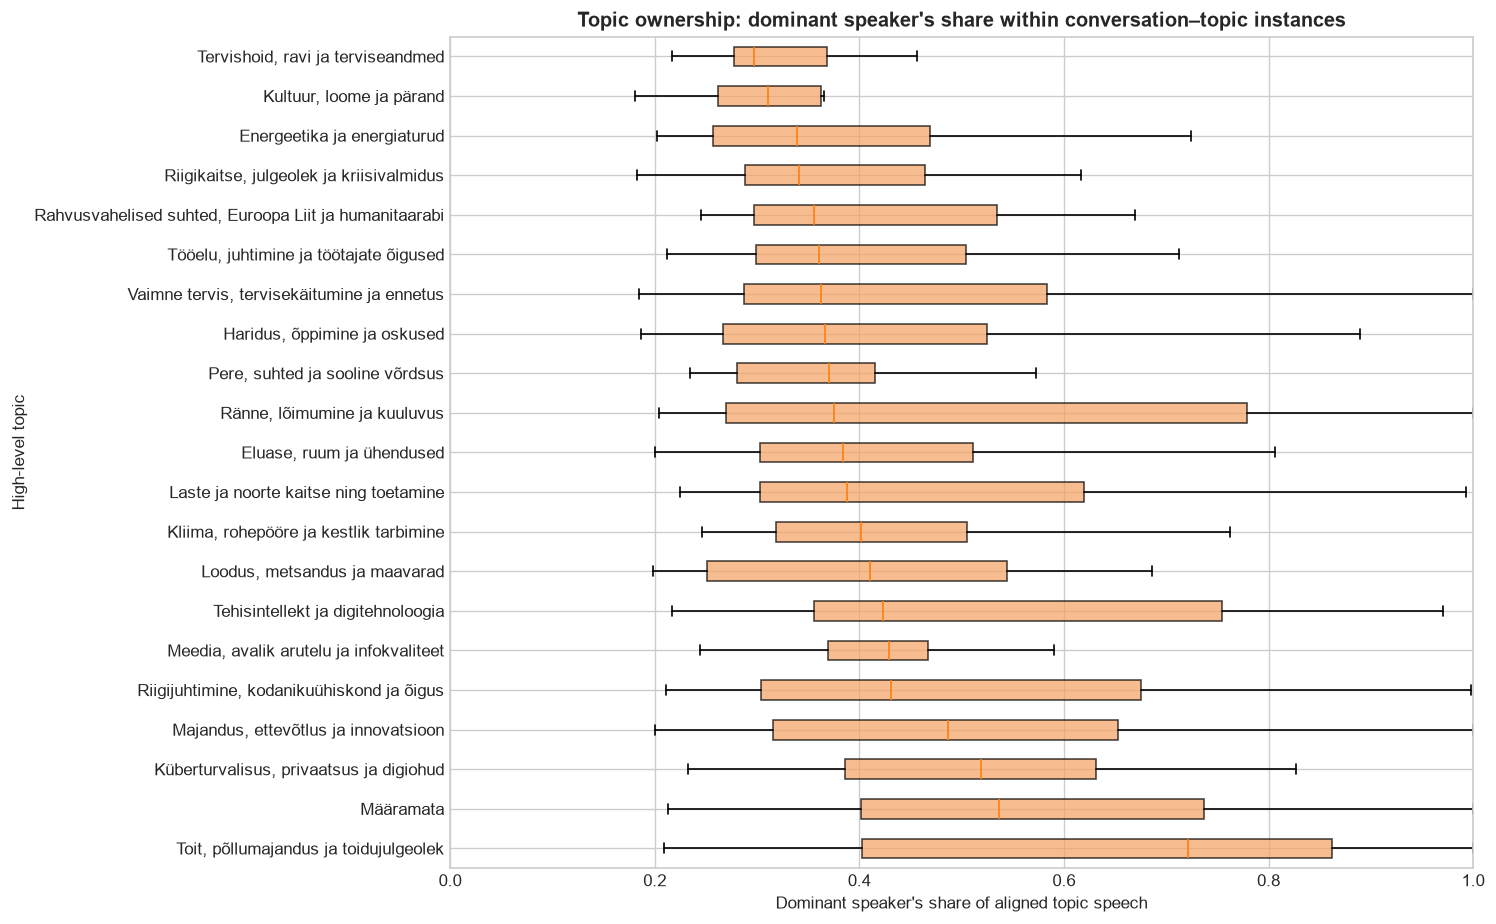

Most collectively discussed conversation–topic instances


,canonical_episode_id,title,high_level_name,total_speech_seconds,unique_speakers,effective_speaker_count,dominant_speaker_share,gini
83,2258666741,Me paneme selle muuseumi kinni!,"Kultuur, loome ja pärand","3,873.489",14,9.316,0.181,0.393
122,2271676364,"Rahvaarv kahaneb, aga ohud kasvavad. Kas Eesti...","Riigikaitse, julgeolek ja kriisivalmidus","4,574.710",10,7.175,0.183,0.344
130,2277338249,Kas lapsi saab panna liikuma_,"Vaimne tervis, tervisekäitumine ja ennetus","4,939.937",14,6.916,0.184,0.540
297,2318409173,Õpilaste tugevustel põhinev haridus – miks ja ...,"Haridus, õppimine ja oskused","4,587.540",15,7.591,0.186,0.528
104,2267420996,"Eesti inimesed soovivad, ökoloogid soovitavad ...","Loodus, metsandus ja maavarad","5,365.774",8,6.433,0.198,0.267
488,2396670927,Kodude kättesaadavus_ kas Eestil on plaan_,"Eluase, ruum ja ühendused","4,278.818",12,7.272,0.201,0.453
329,2323554791,Parlamendierakondade esimeeste debatt,"Majandus, ettevõtlus ja innovatsioon","2,199.424",8,6.302,0.201,0.285
258,2302899446,"Kuidas planeerida tuuleparke nii, et kogukonna...",Energeetika ja energiaturud,"4,632.823",11,6.462,0.202,0.456
325,2323554788,Parlamendierakondade noorte debatt,"Haridus, õppimine ja oskused","1,922.799",8,6.545,0.202,0.254
237,2302899431,Kas elekter lahendab tulevikus kõik meie energ...,Energeetika ja energiaturud,"3,780.107",9,6.347,0.202,0.363


Most speaker-owned conversation–topic instances


,canonical_episode_id,title,high_level_name,total_speech_seconds,unique_speakers,effective_speaker_count,dominant_speaker_share,gini
135,2280202457,Naised ettevõtluses sotsiodraama_ Kuidas tappa...,"Kliima, rohepööre ja kestlik tarbimine",211.252,2,1.001,1.000,0.500
625,2400184983,"Post-it, pastakas ja AI-agent - Eesti.ai prakt...",Määramata,247.707,4,1.003,0.999,0.749
280,2314163819,Miks peaks Lähis-Idas toimuv meile korda minema_,"Riigijuhtimine, kodanikuühiskond ja õigus",125.269,2,1.004,0.998,0.498
101,2267420993,"Mõõdame eurodes, mitte tihumeetrites","Ränne, lõimumine ja kuuluvus",95.649,2,1.005,0.997,0.497
444,2395857144,Vabatahtlikkus_ lõimumise mootor või lõhede pe...,"Ränne, lõimumine ja kuuluvus",82.512,2,1.005,0.997,0.497
383,2387966376,Milliseid riske toob kliima ettevõtete tegevus...,Määramata,152.433,2,1.006,0.997,0.497
602,2400164901,Ühiskondlik ebavõrdsus algab enne kooli – kas ...,Määramata,207.847,2,1.008,0.996,0.496
364,2383011945,Koduseinte vahelt rahvusvahelise poliitikani_ ...,Laste ja noorte kaitse ning toetamine,113.656,2,1.013,0.994,0.494
483,2396670924,Loodusrahvas või ressursirahvas_ miks keskkond...,Energeetika ja energiaturud,116.808,2,1.013,0.993,0.493
256,2302899443,Kohalik energiatootmine on kaitseinvesteering,Määramata,125.252,3,1.013,0.993,0.661


In [7]:
eligible_topics = topic_summary.loc[topic_summary.conversation_topics.ge(3)].index
topic_order = (
    topic_summary.loc[eligible_topics]
    .sort_values("median_dominant_share", ascending=False)
    .index
    .tolist()
)
labels = [name for _, name in topic_order]
values = [
    topic_instances.loc[
        topic_instances.high_level_id.eq(topic[0])
        & topic_instances.high_level_name.eq(topic[1]),
        "dominant_speaker_share",
    ]
    for topic in topic_order
]

fig, ax = plt.subplots(figsize=(11, 9))
plot = ax.boxplot(
    values, orientation="horizontal", tick_labels=labels, showfliers=False, patch_artist=True
)
for box in plot["boxes"]:
    box.set_facecolor("#f4a261")
    box.set_alpha(0.7)
ax.set(
    title="Topic ownership: dominant speaker's share within conversation–topic instances",
    xlabel="Dominant speaker's share of aligned topic speech",
    ylabel="High-level topic",
    xlim=(0, 1),
)
plt.show()

ownership_columns = [
    "canonical_episode_id", "title", "high_level_name", "total_speech_seconds",
    "unique_speakers", "effective_speaker_count", "dominant_speaker_share", "gini",
]
multi_speaker_topics = topic_instances.loc[topic_instances.unique_speakers.ge(2)]
print("Most collectively discussed conversation–topic instances")
display(multi_speaker_topics.nsmallest(15, "dominant_speaker_share")[ownership_columns])
print("Most speaker-owned conversation–topic instances")
display(multi_speaker_topics.nlargest(15, "dominant_speaker_share")[ownership_columns])

## Select one conversation for speaker–topic and turn-taking detail

By default, the notebook chooses a conversation with many substantial topics and several speakers. Set `SELECTED_EPISODE_ID` in the first code cell to inspect another canonical conversation.

Selected: 2254333409 — Kust tuleb raha aastal 2040_


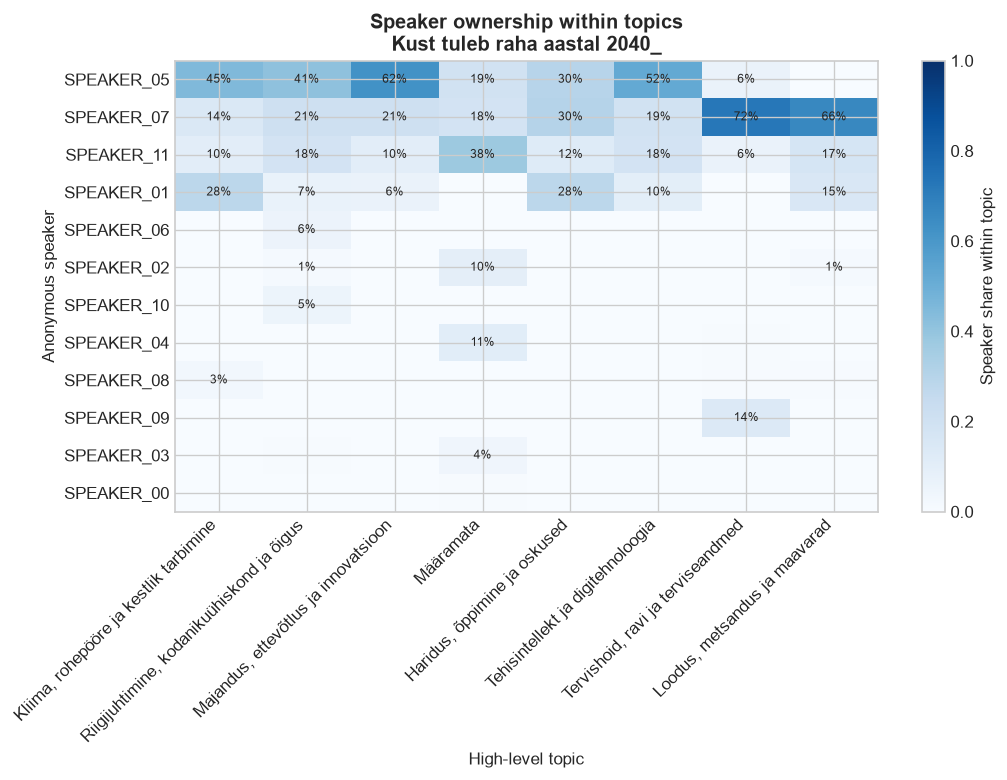

In [8]:
selection_scores = (
    topic_instances.groupby("canonical_episode_id")
    .agg(substantial_topics=("high_level_id", "nunique"), topic_speech=("total_speech_seconds", "sum"))
    .join(conversations.set_index("canonical_episode_id")[["unique_speakers"]])
)
selection_scores["selection_score"] = (
    selection_scores.substantial_topics * np.sqrt(selection_scores.unique_speakers)
)
selected_episode = (
    str(SELECTED_EPISODE_ID)
    if SELECTED_EPISODE_ID is not None
    else selection_scores.selection_score.idxmax()
)
if selected_episode not in canonical_files:
    raise ValueError(f"Unknown canonical episode ID: {selected_episode}")
selected_title = conversations.set_index("canonical_episode_id").loc[selected_episode, "title"]
print(f"Selected: {selected_episode} — {selected_title}")

selected_speaker_topic = (
    speaker_topic.loc[speaker_topic.canonical_episode_id.eq(selected_episode)]
    .groupby(["speaker", "high_level_name"], as_index=False)
    .overlap_seconds.sum()
)
pivot = selected_speaker_topic.pivot(
    index="speaker", columns="high_level_name", values="overlap_seconds"
).fillna(0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]
pivot = pivot.loc[:, pivot.sum(axis=0).sort_values(ascending=False).index]
topic_shares = pivot.div(pivot.sum(axis=0), axis=1)

fig, ax = plt.subplots(figsize=(max(9, 1.1 * len(topic_shares.columns)), max(4, 0.55 * len(topic_shares))))
image = ax.imshow(topic_shares, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(topic_shares.columns)), topic_shares.columns, rotation=45, ha="right")
ax.set_yticks(range(len(topic_shares.index)), topic_shares.index)
for row in range(len(topic_shares.index)):
    for column in range(len(topic_shares.columns)):
        value = topic_shares.iloc[row, column]
        if value >= 0.01:
            ax.text(column, row, f"{value:.0%}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Speaker share within topic")
ax.set(title=f"Speaker ownership within topics\n{selected_title}", xlabel="High-level topic", ylabel="Anonymous speaker")
fig.tight_layout()
plt.show()

## Turn-transition structure

Adjacent runs by the same speaker are collapsed before transitions are counted. Rows are normalized to show whom the floor tends to pass to after each speaker.

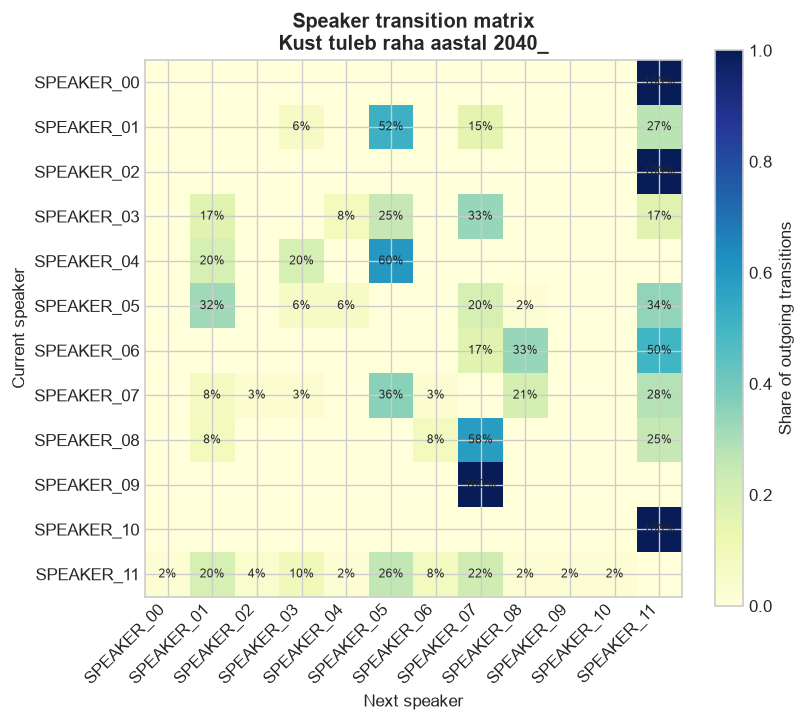

In [9]:
selected_transitions = transitions.loc[
    transitions.canonical_episode_id.eq(selected_episode)
]
transition_matrix = selected_transitions.pivot_table(
    index="from_speaker",
    columns="to_speaker",
    values="transition_count",
    aggfunc="sum",
    fill_value=0,
)
all_speakers = sorted(set(transition_matrix.index) | set(transition_matrix.columns))
transition_matrix = transition_matrix.reindex(index=all_speakers, columns=all_speakers, fill_value=0)
transition_shares = transition_matrix.div(transition_matrix.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(transition_shares, cmap="YlGnBu", vmin=0, vmax=max(0.01, transition_shares.to_numpy().max()))
ax.set_xticks(range(len(all_speakers)), all_speakers, rotation=45, ha="right")
ax.set_yticks(range(len(all_speakers)), all_speakers)
for row in range(len(all_speakers)):
    for column in range(len(all_speakers)):
        value = transition_shares.iloc[row, column]
        if value > 0:
            ax.text(column, row, f"{value:.0%}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Share of outgoing transitions")
ax.set(title=f"Speaker transition matrix\n{selected_title}", xlabel="Next speaker", ylabel="Current speaker")
fig.tight_layout()
plt.show()

## Participation over time

Ten-minute windows advance every five minutes. Speaking time is allocated by interval overlap, so turns crossing a window boundary are divided correctly.

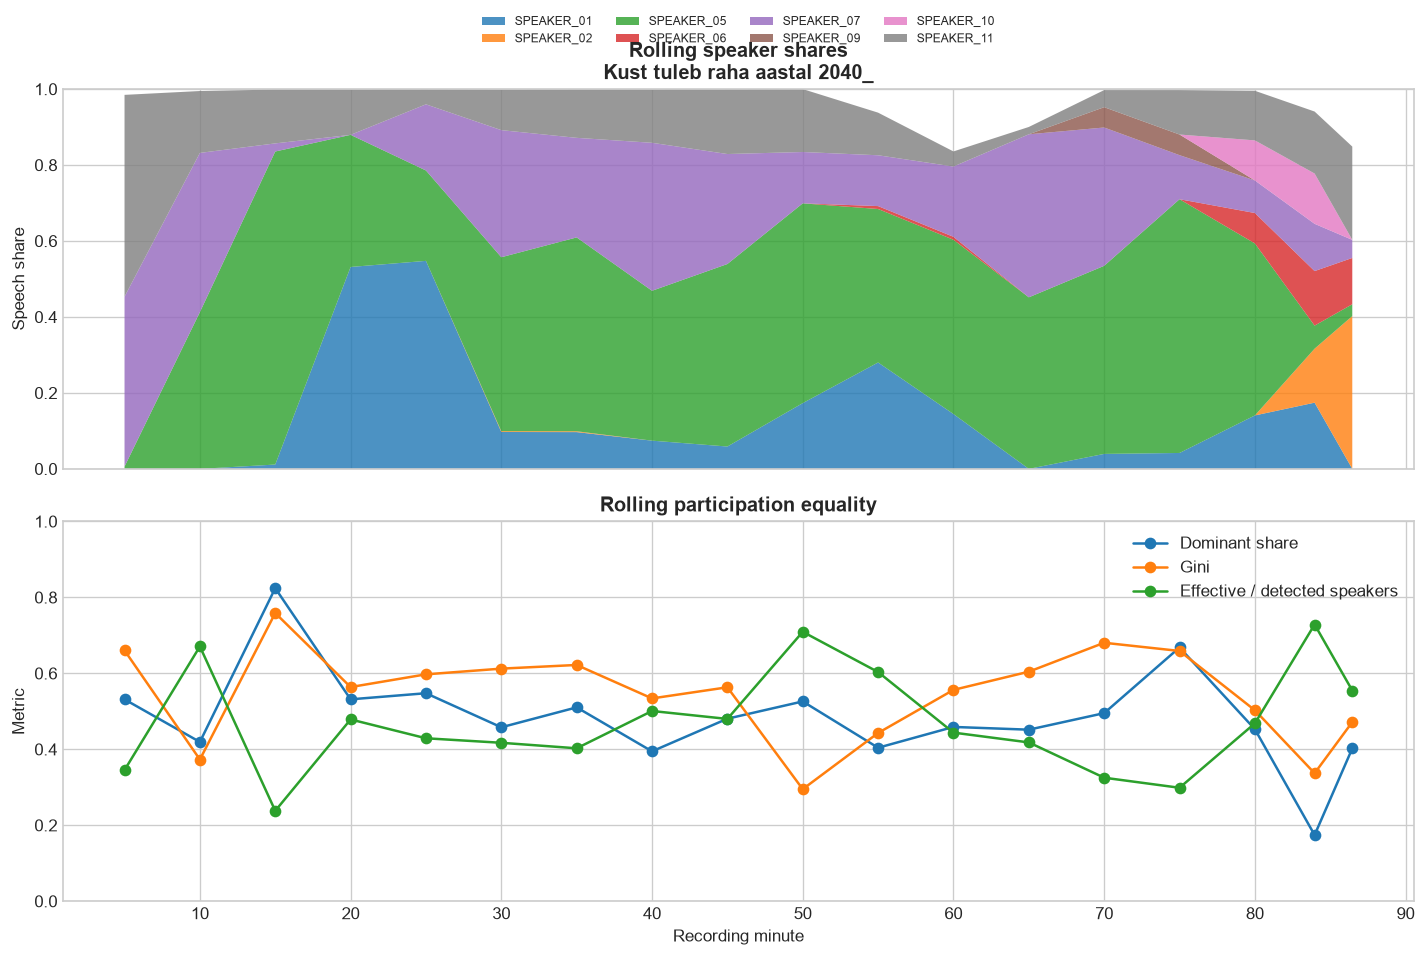

In [10]:
selected_turns = payloads[selected_episode].get("turns", [])
recording_end = max(float(turn["end_seconds"]) for turn in selected_turns)
window_seconds = 600
step_seconds = 300
rolling_rows = []
rolling_speaker_rows = []

for window_start in np.arange(0, max(recording_end - 1, 1), step_seconds):
    window_end = min(window_start + window_seconds, recording_end)
    durations = {}
    for turn in selected_turns:
        overlap = min(window_end, float(turn["end_seconds"])) - max(
            window_start, float(turn["start_seconds"])
        )
        if overlap > 0:
            speaker = str(turn["speaker"])
            durations[speaker] = durations.get(speaker, 0.0) + overlap
    metrics = participation_metrics(durations)
    rolling_rows.append({
        "midpoint_minutes": (window_start + window_end) / 120,
        **metrics,
    })
    total = sum(durations.values())
    for speaker, duration in durations.items():
        rolling_speaker_rows.append({
            "midpoint_minutes": (window_start + window_end) / 120,
            "speaker": speaker,
            "speech_share": duration / total if total else 0,
        })

rolling = pd.DataFrame(rolling_rows)
rolling_speakers = pd.DataFrame(rolling_speaker_rows)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
top_speakers = (
    rolling_speakers.groupby("speaker").speech_share.mean().nlargest(8).index
)
speaker_share_pivot = (
    rolling_speakers.loc[rolling_speakers.speaker.isin(top_speakers)]
    .pivot(index="midpoint_minutes", columns="speaker", values="speech_share")
    .fillna(0)
)
axes[0].stackplot(
    speaker_share_pivot.index,
    *[speaker_share_pivot[column] for column in speaker_share_pivot.columns],
    labels=speaker_share_pivot.columns,
    alpha=0.8,
)
axes[0].set(title=f"Rolling speaker shares\n{selected_title}", ylabel="Speech share", ylim=(0, 1))
axes[0].legend(ncol=4, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 1.22))

axes[1].plot(rolling.midpoint_minutes, rolling.dominant_speaker_share, marker="o", label="Dominant share")
axes[1].plot(rolling.midpoint_minutes, rolling.gini, marker="o", label="Gini")
axes[1].plot(
    rolling.midpoint_minutes,
    rolling.effective_speaker_count / rolling.unique_speakers,
    marker="o",
    label="Effective / detected speakers",
)
axes[1].set(xlabel="Recording minute", ylabel="Metric", ylim=(0, 1), title="Rolling participation equality")
axes[1].legend()
fig.tight_layout()
plt.show()

## Opening versus closing participation

The first and last 10% of each recording are compared using duration allocated inside those windows. Positive change means the closing became more concentrated than the opening.

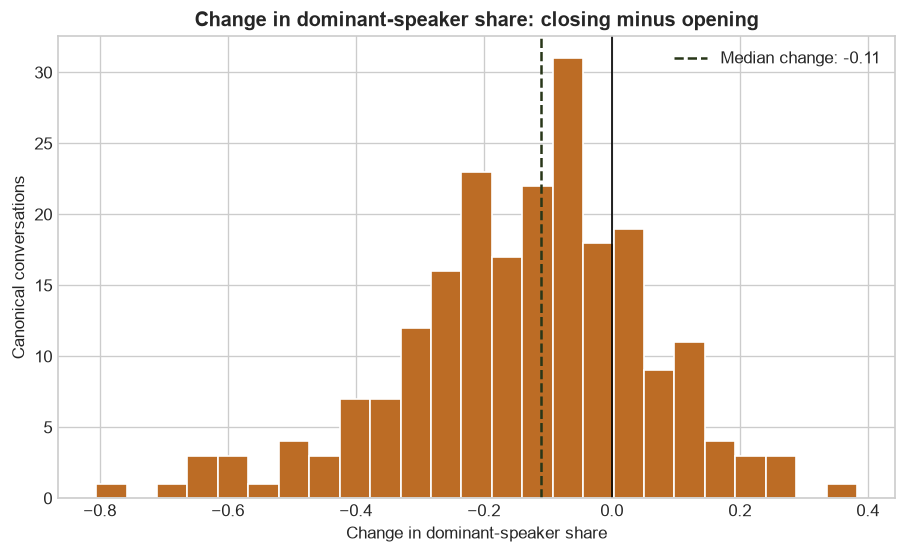

,value
Conversations,219.000
Closing more concentrated,50.000
Closing more equal,169.000
Median dominance change,-0.111


In [11]:
phase_rows = []
for episode_id, payload in payloads.items():
    turns = payload.get("turns", [])
    if not turns:
        continue
    recording_end = max(float(turn["end_seconds"]) for turn in turns)
    for phase, start, end in [
        ("opening", 0, recording_end * 0.1),
        ("closing", recording_end * 0.9, recording_end),
    ]:
        durations = {}
        for turn in turns:
            overlap = min(end, float(turn["end_seconds"])) - max(start, float(turn["start_seconds"]))
            if overlap > 0:
                speaker = str(turn["speaker"])
                durations[speaker] = durations.get(speaker, 0.0) + overlap
        phase_rows.append({
            "canonical_episode_id": episode_id,
            "phase": phase,
            **participation_metrics(durations),
        })

phases = pd.DataFrame(phase_rows)
phase_comparison = phases.pivot(
    index="canonical_episode_id",
    columns="phase",
    values=["dominant_speaker_share", "gini", "effective_speaker_count"],
)
dominance_change = (
    phase_comparison["dominant_speaker_share"]["closing"]
    - phase_comparison["dominant_speaker_share"]["opening"]
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(dominance_change.dropna(), bins=25, color="#bc6c25", edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.axvline(dominance_change.median(), color="#283618", linestyle="--", label=f"Median change: {dominance_change.median():+.2f}")
ax.set(
    title="Change in dominant-speaker share: closing minus opening",
    xlabel="Change in dominant-speaker share",
    ylabel="Canonical conversations",
)
ax.legend()
plt.show()

display(
    pd.Series({
        "Conversations": len(dominance_change),
        "Closing more concentrated": int(dominance_change.gt(0).sum()),
        "Closing more equal": int(dominance_change.lt(0).sum()),
        "Median dominance change": dominance_change.median(),
    }, name="value").to_frame()
)

## Interpretation cautions

- These results describe diarization and topic-model output, not verified human identities or ground-truth participation.
- Speaker splitting inflates speaker counts and apparent equality; speaker merging does the opposite.
- Topic ownership is based on temporal overlap between diarization turns and semantic chunks. It does not imply authorship, expertise, agreement, or control over the framing.
- Overlapping speech can produce more speaker-overlap time than wall-clock time.
- Conversation–topic instances with little aligned speech are unstable; use `MIN_TOPIC_SPEECH_SECONDS` to set an appropriate threshold.
- Aggregate comparisons use canonical conversations, while the 264-file mapping remains available for coverage and duplicate-quality checks.